In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("smartcart_customers.csv")

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

## Data Preprocessing 

# handle missing values

In [6]:
df["Income"] = df["Income"].fillna(df["Income"].median())

## Feature Engineering

In [7]:
#Age
df["Age"] = 2026-df["Year_Birth"]


In [8]:
#date time
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)

reference_date = df["Dt_Customer"].max()

df["Customer_tenure_day"] = (reference_date - df["Dt_Customer"]).dt.days

In [9]:
#spending

df["Total Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_tenure_day', 'Total Spending'],
      dtype='object')

In [11]:
df["Total_children"] = df["Kidhome"] + df["Teenhome"]

In [12]:
#Education status
df["Education"] = df["Education"].replace({
                            "Basic" : "UnderGraduate",
                            "2n Cycle" : "UnderGraduate",
                            "Graduation" : "Graduate",
                            "PhD" : "PostGraduate",
                            "Master" : "PostGraduate"
                            })

In [13]:
#Marital_Status

df["Marital_Status"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone",
    "Widow": "Alone","YOLO": "Alone",
    "Absurd": "Alone",
})

df["Marital_Status"].value_counts()

Marital_Status
Partner    1444
Alone       796
Name: count, dtype: int64

# Drop Columns

In [14]:
col_to_drop = ["ID", "Year_Birth", "Kidhome", "Teenhome", "Dt_Customer", "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

df_cleaned = df.drop(columns = col_to_drop)

In [15]:
df_cleaned.columns

Index(['Education', 'Marital_Status', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'Customer_tenure_day', 'Total Spending', 'Total_children'],
      dtype='object')

In [16]:
df_cleaned.shape

(2240, 15)

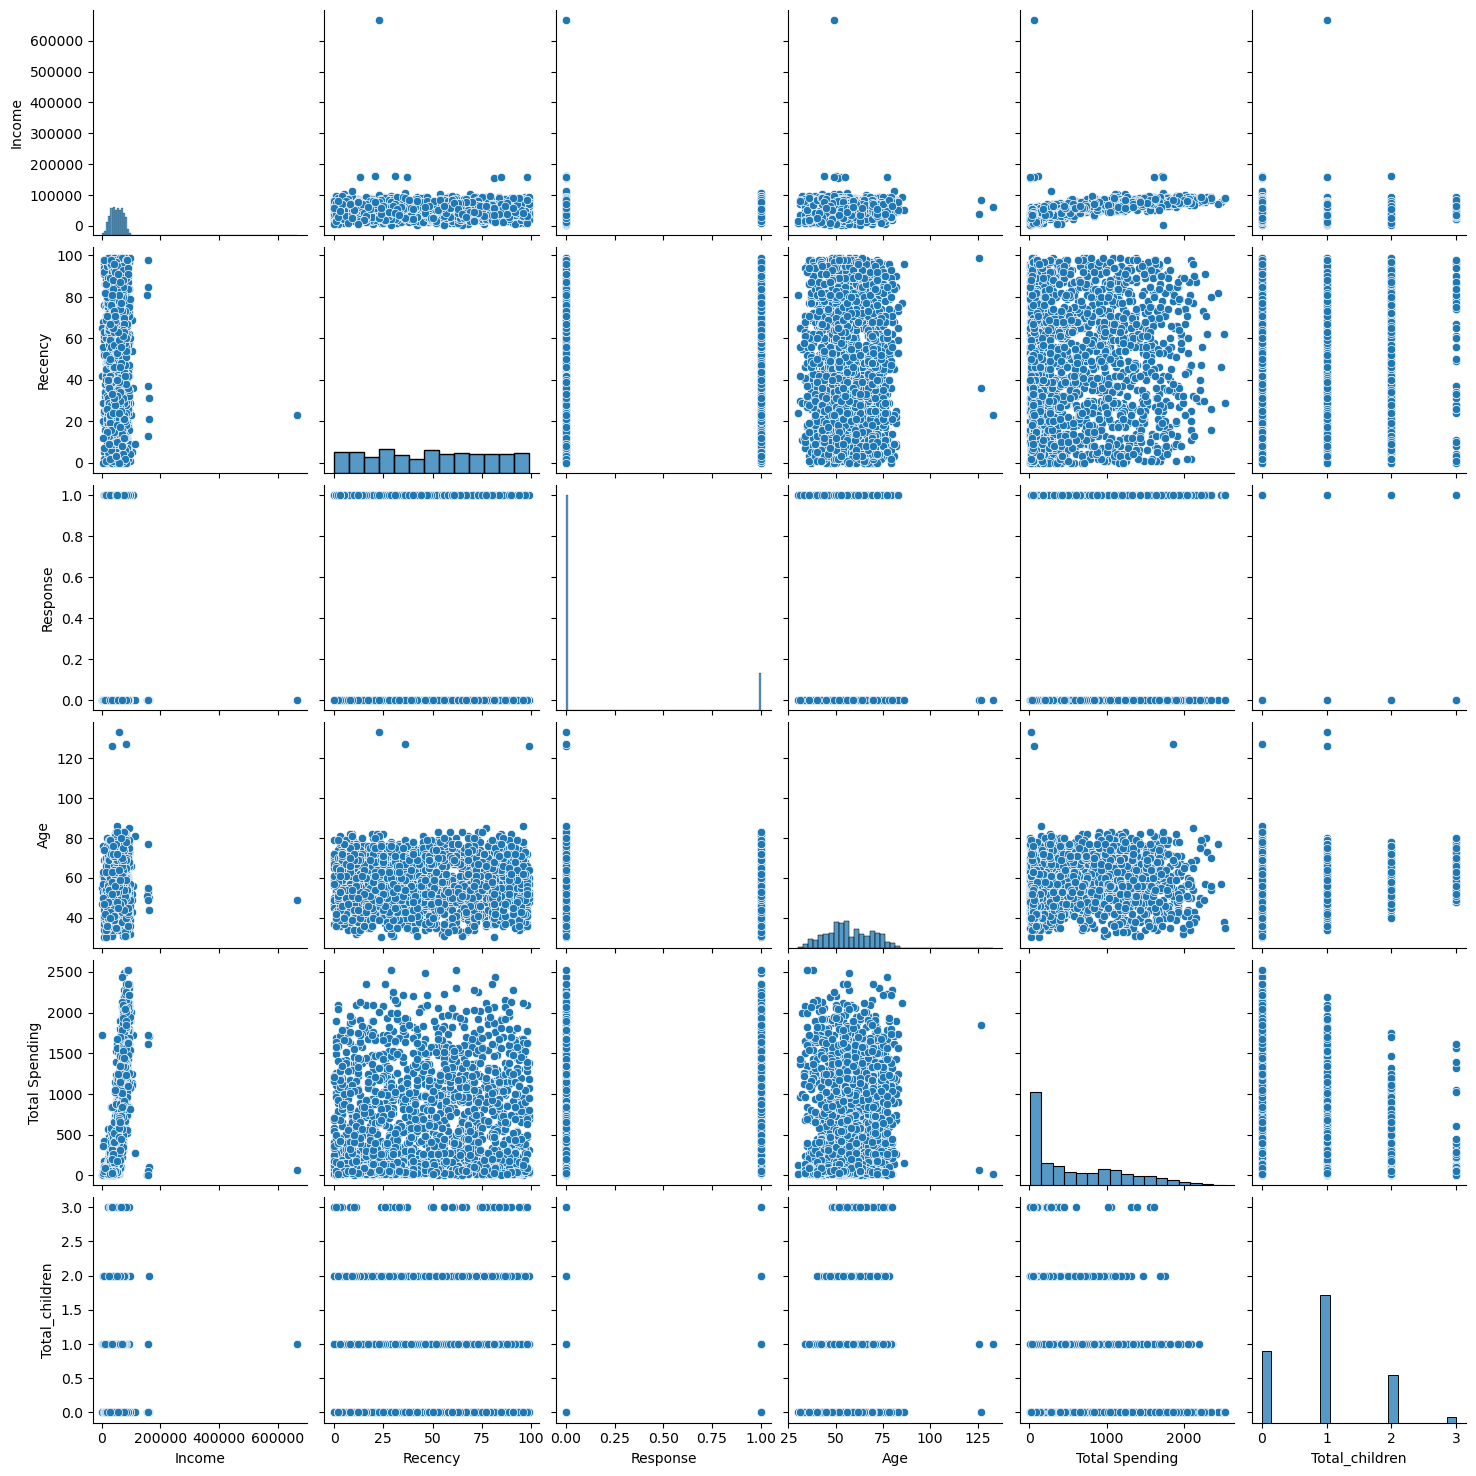

In [17]:
# detect outlier

cols = ["Income", "Recency", "Response", "Age", "Total Spending", "Total_children"]

#relative plot for some feature - pair plot

sns.pairplot(df_cleaned[cols])

In [18]:
#remove outliers

print("Data size with outliers ",len(df_cleaned))
df_cleaned = df_cleaned[(df_cleaned["Income"]<600_000)]
df_cleaned = df_cleaned[(df_cleaned["Age"]<85)]
print("Data without outliers", len(df_cleaned))

Data size with outliers  2240
Data without outliers 2234


# HeatMap

In [19]:
corr = df_cleaned.corr(numeric_only = True)

<Axes: >

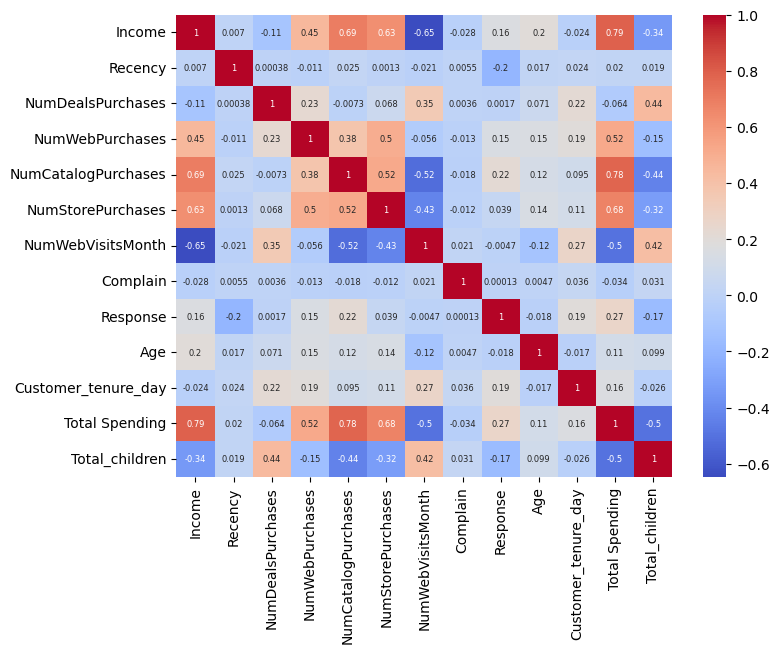

In [20]:
plt.figure(figsize = (8, 6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size" : 6},
    cmap = "coolwarm"
)

In [21]:
from sklearn.preprocessing import OneHotEncoder

In [22]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Marital_Status"]

encoded_cols = ohe.fit_transform(df_cleaned[cat_cols])


In [23]:
enc_df = pd.DataFrame(encoded_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index = df_cleaned.index)

In [24]:
#combine both dataset
encoded_df = pd.concat([df_cleaned.drop(columns = cat_cols), enc_df], axis = 1)


In [25]:
encoded_df.shape

(2234, 18)

In [26]:
df_cleaned.shape

(2234, 15)

# Scaling

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
X = encoded_df

In [29]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Visualization

In [30]:
#2D
from sklearn.decomposition import PCA

In [31]:
pca = PCA(n_components = 3)

x_pca = pca.fit_transform(X_scaled)

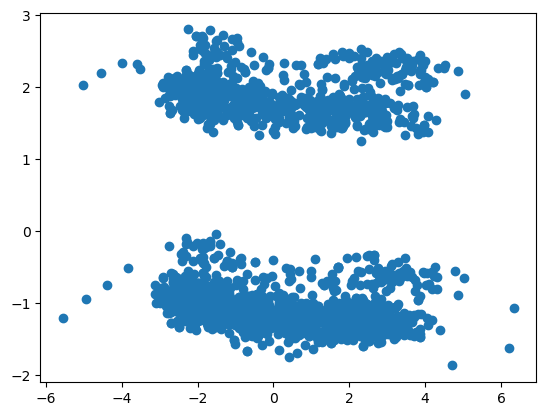

In [32]:
plt.scatter(x_pca[:, 0], x_pca[:, 1])

In [33]:
pca.explained_variance_ratio_

array([0.23157687, 0.11385516, 0.1041395 ])

Text(0.5, 0, 'PC3')

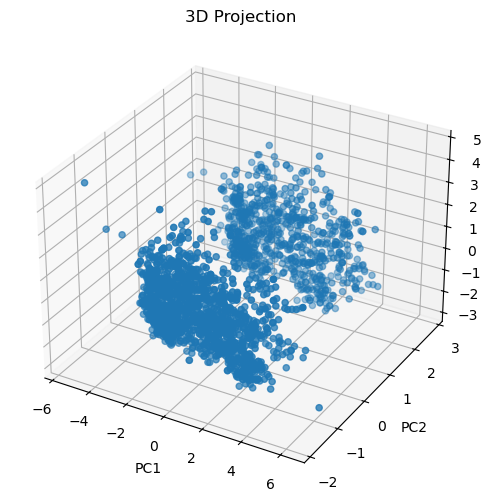

In [34]:
# plot

fig = plt.figure(figsize = (8, 6))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2])

ax.set_title("3D Projection")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

# Analyze K-value
## 1. Elbow Method

In [35]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [36]:
wcss = []
for k in range(1, 11):
    kmean = KMeans(n_clusters = k, random_state = 42)
    kmean.fit_predict(x_pca)
    wcss.append(kmean.inertia_)
    
    

In [37]:
knee = KneeLocator(range(1, 11), wcss, curve = "convex", direction = "decreasing")
optimal_k = knee.elbow

In [38]:
print("Best K-value :", optimal_k)

Best K-value : 3


Text(0, 0.5, 'wcss')

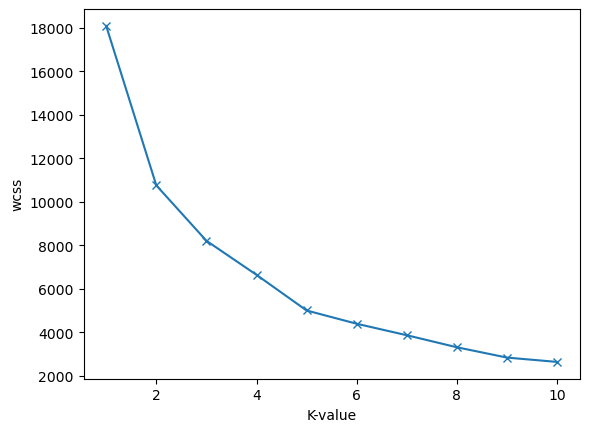

In [39]:
plt.plot(range(1, 11), wcss, marker = "x")
plt.xlabel("K-value")
plt.ylabel("wcss")

In [44]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca, labels)
    scores.append(score)

Text(0, 0.5, 'Silhouette score')

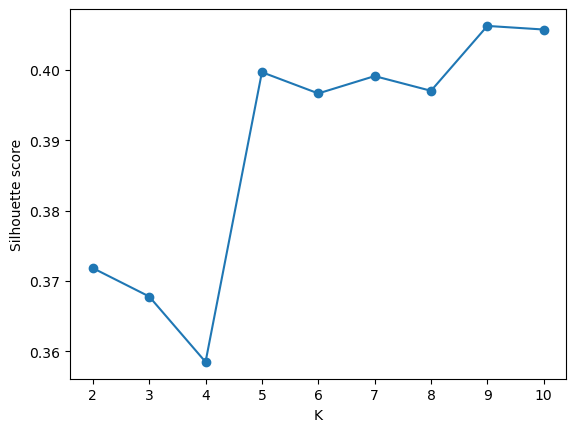

In [46]:
#plot
plt.plot(range(2, 11), scores, marker = 'o')
plt.xlabel("K")
plt.ylabel("Silhouette score")

Text(0, 0.5, 'SS')

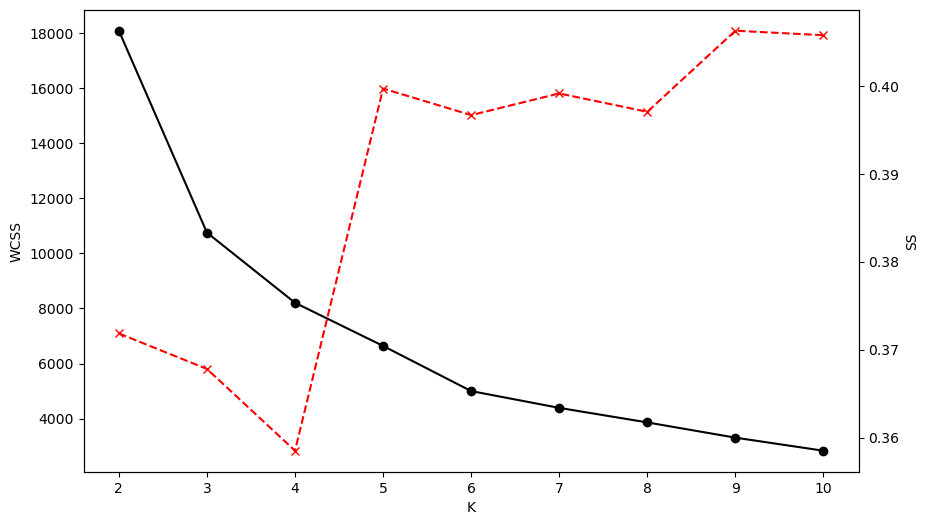

In [49]:
#combine both plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker = 'o', color = 'black')
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("SS")

## Clustering

In [51]:
# K_means

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(x_pca)

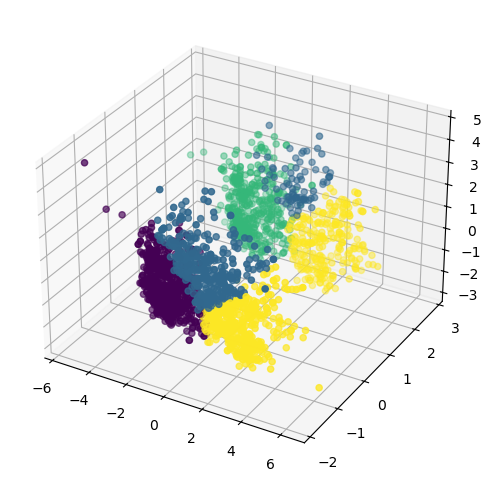

In [55]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_kmeans)

In [56]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [58]:
agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(x_pca)

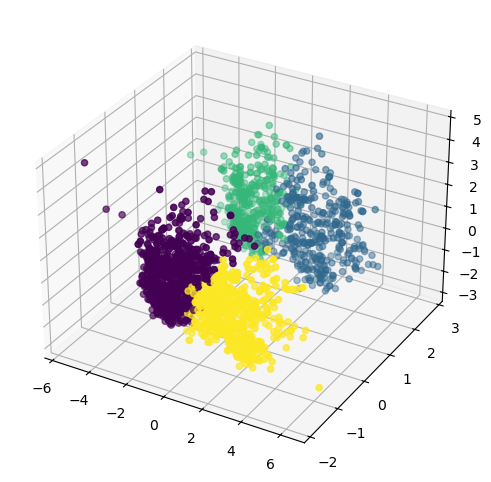

In [60]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_agg)

# Characterization of Clusters

In [63]:
X["cluster"] = labels_agg
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_tenure_day,Total Spending,Total_children,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Marital_Status_Alone,Marital_Status_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,3
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

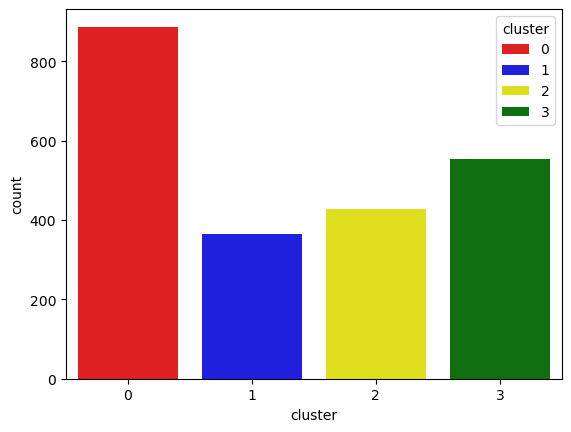

In [64]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x=X["cluster"], palette=pal, hue=X["cluster"])

<Axes: xlabel='Total Spending', ylabel='Income'>

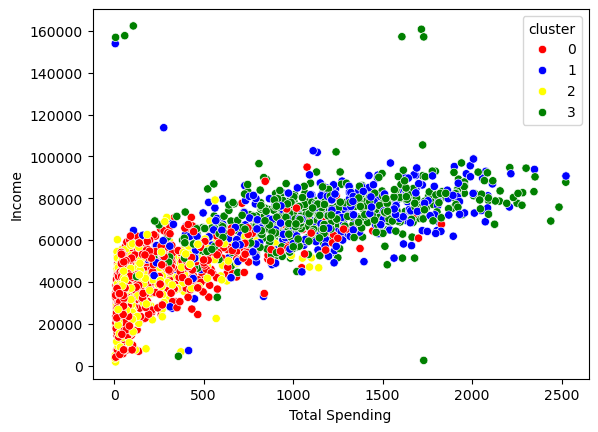

In [66]:
# Income & Spending patterns

sns.scatterplot(x=X["Total Spending"], y=X["Income"], hue=X["cluster"], palette=pal)

In [67]:
# Cluster Summary

cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39504.092446  49.331454           2.706877         3.192785   
1        69691.875342  51.435616           1.846575         5.673973   
2        37079.973131  47.287383           2.607477         2.742991   
3        71613.689531  48.521661           1.821300         5.510830   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   1.016911           4.187148           6.528749  0.009019   
1                   4.868493           8.232877           3.756164  0.005479   
2                   0.850467           3.679907           6.630841  0.011682   
3                   5.236462           8.404332           3.404332  0.009025   

         Response        Age  Customer_tenure_day  Total Spending  \
cluster          

In [68]:
cluster_summary.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_tenure_day,Total Spending,Total_children,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Marital_Status_Alone,Marital_Status_Partner
cluster,,,,,,,,,,,,,,,,,,
0,39504.092446,49.331454,2.706877,3.192785,1.016911,4.187148,6.528749,0.009019,0.092446,56.013529,354.487035,232.187148,1.284104,0.429538,0.426156,0.144307,0.0,1.0
1,69691.875342,51.435616,1.846575,5.673973,4.868493,8.232877,3.756164,0.005479,0.309589,58.528767,373.367123,1147.841096,0.473973,0.561644,0.372603,0.065753,1.0,0.0
2,37079.973131,47.287383,2.607477,2.742991,0.850467,3.679907,6.630841,0.011682,0.147196,55.778037,340.955607,173.981308,1.285047,0.474299,0.387850,0.137850,1.0,0.0
3,71613.689531,48.521661,1.821300,5.510830,5.236462,8.404332,3.404332,0.009025,0.137184,58.824910,349.460289,1179.303249,0.476534,0.608303,0.312274,0.079422,0.0,1.0


In [1]:
arr = [2, 4, 6]
s = 0
for i in range(1, len(arr)):
    s += arr[i]
print(s)

10
